jupyter notebook --ip=192.168.50.85 --port=8888

## 🔵 What Is Logistic Regression?

Logistic Regression is used when the output is a category, not a number.
Example predictions:

* Will a student pass or fail? → Yes / No
* Is an email spam or not? → Spam / Not Spam
* Will a customer buy or not? → Buy / Not Buy

So instead of predicting a number (like linear regression), it predicts a probability between 0 and 1.

1️⃣ Collect and Prepare the Data

* Load your dataset
* Identify features (X) and target (Y)
* Make sure the target is binary (0/1)

2️⃣ Split the Data

Divide your data into:

* Training set → used to learn
* Test set → used to evaluate
* (Example: 80% train, 20% test)

3️⃣ Preprocess the Data

* ✔️ Handle missing values
* ✔️ Remove or treat outliers
* ✔️ Encode categorical data
* ✔️ Scale numerical features (important for logistic regression)

Use StandardScaler or MinMaxScaler.

4️⃣ Check for Multicollinearity

Ensure features are not too strongly correlated.

Tools to use:

* Correlation matrix
* VIF (Variance Inflation Factor)

5️⃣ Train the Logistic Regression Model

* Fit the model on the training data:
  * model.fit(X_train, y_train)

The algorithm will:

* Use sigmoid to convert outputs to probability
* Adjust weights using gradient descent
* Minimize log loss

6️⃣ Make Predictions

Two types of prediction:

* a) Probability Prediction
  * model.predict_proba(X_test) → values between 0 and 1

* b) Class Prediction
  * model.predict(X_test) → 0 or 1

7️⃣ Evaluate the Model

Use evaluation metrics like:

* Accuracy
* Precision
* Recall
* F1-score
* Confusion Matrix
* ROC Curve + AUC

These tell how well your model performs.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv('diabetes2.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
display(df.describe())

print("\nMissing values per column:")
print(df.isna().sum())


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## ⭐ What is Class Balance?

When performing Logistic Regression (or any classification task), you must check:

How many samples belong to each class?

Example for diabetes dataset:

* Class 0 = No diabetes
* Class 1 = Diabetes

If your dataset has:

* 500 samples of class 0
* 100 samples of class 1

Then the dataset is imbalanced.

In [ ]:
print("Class counts:")
print(df["Outcome"].value_counts())

print("\nClass proportion:")
print(df["Outcome"].value_counts(normalize=True))

Class counts:
Outcome
0    500
1    268
Name: count, dtype: int64

Class proportion:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


## ⭐ What Is Correlation?

Correlation tells how strongly two variables move together.

Think of it as:

 * “If one feature increases, what does the other feature do?”

Correlation value ranges from –1 to +1:

| Value  | Meaning                      | Example                        |
| ------ | ---------------------------- | ------------------------------ |
| **+1** | Perfect positive correlation | Height ↑ → Weight ↑            |
| **0**  | No relationship              | Shoe size vs IQ                |
| **–1** | Perfect negative correlation | Age ↑ → Remaining life years ↓ |


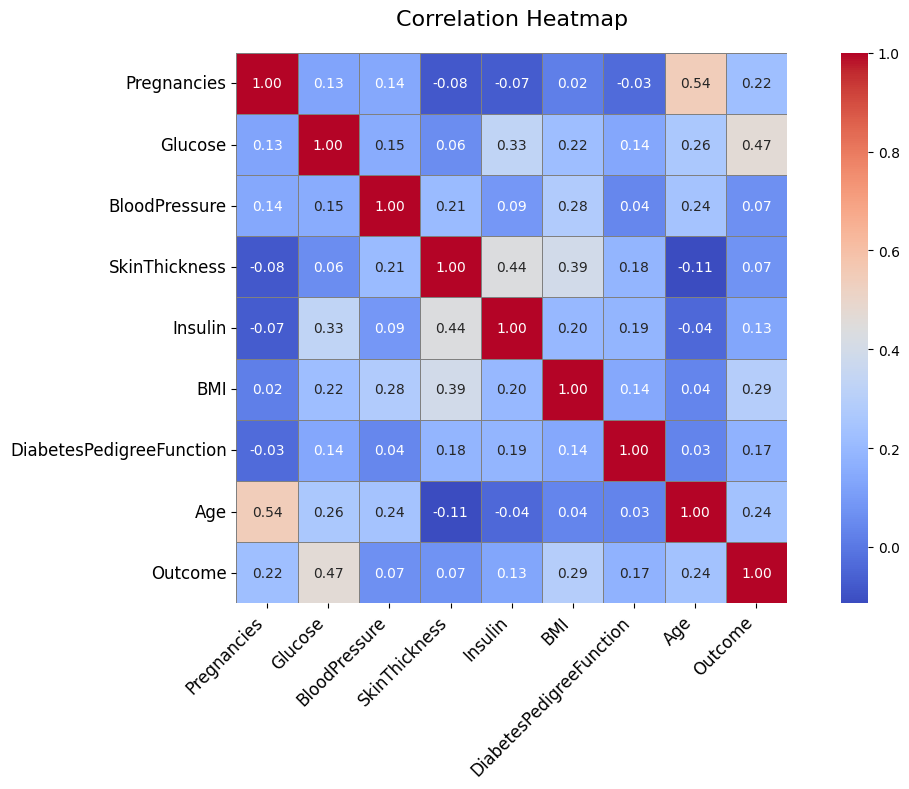

In [ ]:
plt.figure(figsize=(12, 8))

# Compute correlation matrix
corr = df.corr()

# Improved heatmap
sns.heatmap(
    corr,
    annot=True,          # show correlation values
    fmt=".2f",           # limit numbers to 2 decimals
    cmap="coolwarm",     # color range
    linewidths=.5,       # thin lines between cells
    linecolor='gray',    # line color
    cbar=True,           # show color bar
    square=True          # square cells for better symmetry
)

plt.title("Correlation Heatmap", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X.head(), y.head()

(   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
 0            6      148             72             35        0  33.6   
 1            1       85             66             29        0  26.6   
 2            8      183             64              0        0  23.3   
 3            1       89             66             23       94  28.1   
 4            0      137             40             35      168  43.1   
 
    DiabetesPedigreeFunction  Age  
 0                     0.627   50  
 1                     0.351   31  
 2                     0.672   32  
 3                     0.167   21  
 4                     2.288   33  ,
 0    1
 1    0
 2    1
 3    0
 4    1
 Name: Outcome, dtype: int64)

## ⭐ 1️⃣ What is random_state?

random_state controls the randomness of how the data is split.

Think of it like setting a seed so that you always get the same split every time you run the code.

## ⭐ 2️⃣ What is stratify=y?

Stratification ensures that both the train and test sets have the same class proportion as the original dataset.

In other words:

* If 35% of people in the full dataset have diabetes,
* then the train set will also have 35%,
* and the test set will also have 35%.

Without stratify, you may accidentally get:
* Train set → 20% diabetic
* Test set → 50% diabetic

This can ruin model evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((614, 8), (154, 8))

## ⭐ The Purpose: Feature Scaling

Different features in your dataset may have very different ranges:

| Feature       | Example Value Range |
| ------------- | ------------------- |
| Glucose       | 60 – 200            |
| Age           | 20 – 80             |
| BMI           | 15 – 50             |
| SkinThickness | 0 – 100             |

If you don’t scale them, some features will dominate others.

Logistic Regression needs scaled data for stable and correct learning

StandardScaler transforms every feature so that:
* Mean becomes 0
* Standard deviation becomes 1

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## ✔ You are creating a Logistic Regression model

LogisticRegression() creates a machine learning model that will learn to:

* Find a relationship between features (X) and the target (y)
* Predict whether a patient has diabetes (0 or 1)

## ✔ Why do we use max_iter=1000?

Logistic Regression uses Gradient Descent to find the best weights.

Sometimes, especially with real data like diabetes, the algorithm needs more steps to converge (finish learning).

* Default iterations = 100:   This may be too small → model may not converge

So we increase it to 1000

This ensures:

* The model has enough time to learn
* It avoids warnings like “ConvergenceWarning: Increase max_iter”

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


| Code              | Explanation                              |
| ----------------- | ---------------------------------------- |
| `predict()`       | Gives class label (0 or 1)               |
| `predict_proba()` | Gives probability for each class         |
| `[:,1]`           | Select probability of class 1 (diabetes) |


In [ ]:
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]  # probability of class 1


## ✔ Precision
* Out of the patients predicted as diabetic (1), how many were actually diabetic?
* High precision = few false alarms.

## ✔ Recall (Sensitivity)
* Out of all REAL diabetic patients, how many did the model correctly detect?
* High recall = fewer missed positive cases (important in medical problems).

## ✔ F1-Score
Useful when:
* Classes are imbalanced
* You want a measure that balances both false positives & false negatives

## ✔ Support
* Number of samples belonging to each class in y_test.

## ✔ What is ROC-AUC?
* ROC = Receiver Operating Characteristic
* AUC = Area Under Curve
It tells how well the model can separate the two classes (0 and 1).

#### ✔ Meaning of AUC values:
| AUC             | Interpretation                    |
| --------------- | --------------------------------- |
| **0.90 – 1.0**  | Excellent model                   |
| **0.80 – 0.90** | Good model                        |
| **0.70 – 0.80** | Fair model                        |
| **0.60 – 0.70** | Weak model                        |
| **0.50**        | Useless (same as random guessing) |


#### ✔ Why does ROC-AUC use y_proba, not y_pred?
* Because ROC evaluates probability scores, not fixed class labels.
* Threshold changes → Model performance changes.
* AUC summarizes performance across all thresholds.

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ROC-AUC
auc = roc_auc_score(y_test, y_proba)
print("ROC-AUC:", auc)


Accuracy: 0.7142857142857143

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.82      0.79       100
           1       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154

ROC-AUC: 0.8229629629629629


In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[82, 18],
       [26, 28]])

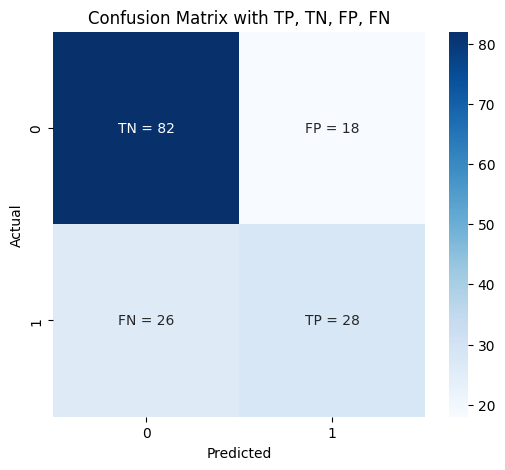

In [ ]:
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

annot = np.array([
    [f"TN = {TN}", f"FP = {FP}"],
    [f"FN = {FN}", f"TP = {TP}"]
])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=annot, fmt='', cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix with TP, TN, FP, FN")
plt.show()


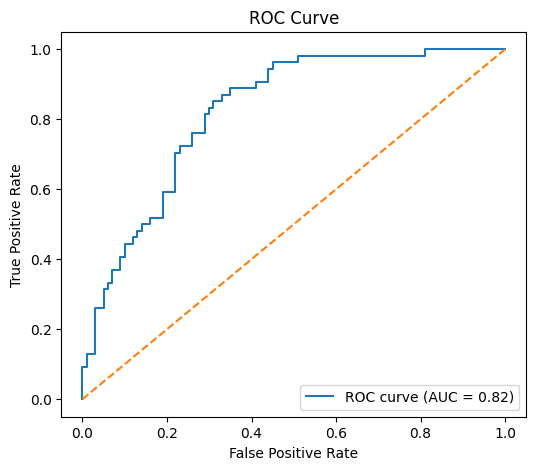

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [ ]:
!pip install gradio

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import gradio as gr
import numpy as np

def predict_diabetes(Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age):
    # Order must match your training DataFrame
    data = np.array([[Pregnancies, Glucose, BloodPressure, SkinThickness,
                      Insulin, BMI, DiabetesPedigreeFunction, Age]])

    prediction = model.predict(data)[0]
    prob = model.predict_proba(data)[0][1]

    result = "Diabetic" if prediction == 1 else "Non-Diabetic"
    return f"Prediction: {result}\nProbability of Diabetes: {prob:.2f}"

# Build Gradio Inputs
inputs = [
    gr.Slider(0, 20, step=1, label="Pregnancies"),
    gr.Slider(0, 200, label="Glucose"),
    gr.Slider(0, 150, label="Blood Pressure"),
    gr.Slider(0, 1000, label="Skin Thickness"),
    gr.Slider(0, 20000, label="Insulin"),
    gr.Slider(0, 70, label="BMI"),
    gr.Slider(0, 5, label="Diabetes Pedigree Function"),
    gr.Slider(1, 100, label="Age")
]

outputs = gr.Textbox(label="Prediction Result")

# Interface
gui = gr.Interface(
    fn=predict_diabetes,
    inputs=inputs,
    outputs=outputs,
    title="Diabetes Prediction App",
    description="Adjust the sliders to input patient information and predict diabetes."
)

gui.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
